# Stroke Prediction (Classification)

**Problem:** predict whether a patient will have a stroke (1) or not (0) from health and demographic data.
**Challenge:** only ~4.9% of patients had a stroke (strong class imbalance).
**Main metric:** recall on the stroke class (a missed stroke is the costly error), plus precision, F1 and PR-AUC.

## 1. Setup & load

In [1]:
import pandas as pd
from pathlib import Path

Clean_Path = Path("../data/processed")/"stroke_clean.csv"

df_clean = pd.read_csv(Clean_Path)

In [2]:
df_clean.shape

(5109, 11)

In [3]:
X = df_clean.drop(columns="stroke")
y = df_clean["stroke"]

In [4]:
print(X.shape, y.shape)
X.head()

(5109, 10) (5109,)


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked


## 2. Split & preprocessing

In [5]:
from sklearn.model_selection import train_test_split

# stratify=y keeps the ~4.9% stroke rate in both sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape)
print(X_test.shape)

(4087, 10)
(1022, 10)


In [6]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 4087 entries, 845 to 5052
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             4087 non-null   str    
 1   age                4087 non-null   float64
 2   hypertension       4087 non-null   int64  
 3   heart_disease      4087 non-null   int64  
 4   ever_married       4087 non-null   str    
 5   work_type          4087 non-null   str    
 6   Residence_type     4087 non-null   str    
 7   avg_glucose_level  4087 non-null   float64
 8   bmi                3924 non-null   float64
 9   smoking_status     4087 non-null   str    
dtypes: float64(3), int64(2), str(5)
memory usage: 351.2 KB


In [7]:
numeric_columns = X_train.select_dtypes(include="float64").columns
categorical_columns = X_train.select_dtypes(include="str").columns
# binary 0/1 columns need no transform, they pass through via remainder
binary_columns = X_train.select_dtypes(include="int64").columns

In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder

# median imputation + a 'bmi was missing' flag (missing bmi had a much higher stroke rate)
numeric_preprocessor = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler())

preprocessor = make_column_transformer(
    (numeric_preprocessor, numeric_columns),
    (OneHotEncoder(handle_unknown="ignore"), categorical_columns),
    remainder="passthrough"
)

# fit here only to check the output; in the models it is refit inside every CV fold
new_data = preprocessor.fit_transform(X_train)


In [9]:
pd.DataFrame(new_data).isna().sum()

0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
14    0
15    0
16    0
17    0
18    0
19    0
20    0
dtype: int64

## 3. Cross-validation setup
Stratified 5-fold CV on the training set only, so every fold keeps the ~4.9% stroke rate. The preprocessor sits **inside** each pipeline, so imputation and scaling are learned per fold (no leakage).

**Validation:** instead of one fixed validation set, the 5 CV folds act as the validation sets (each fold is held out once). All model choices use CV; the test set is used once at the end.

In [10]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# zero_division=0 avoids warnings when a model predicts no strokes at all
scoring = {
    "recall": "recall",
    "precision": make_scorer(precision_score, zero_division=0),
    "f1": "f1",
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
}

def cv_summary(model):
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    return {m: res[f"test_{m}"].mean() for m in scoring}

## 4. Baseline & model comparison
- **Baseline:** always predict "no stroke". It scores ~95% accuracy but catches **zero** strokes, which is why accuracy is not our metric.
- **Models:** Logistic Regression, Random Forest and HistGradientBoosting, all with `class_weight="balanced"` so the rare stroke class is not ignored. Random Forest uses `min_samples_leaf=10` to stop it memorising the few positive cases.

| Model | Complexity | Interpretability | Compute cost |
|---|---|---|---|
| Logistic Regression | Low | High: one coefficient per feature | Very low |
| Random Forest | Medium–high | Medium: feature importances only | Medium |
| HistGradientBoosting | High | Low–medium | Low–medium |

Interpretability matters in a medical setting, which favours Logistic Regression if performance is similar.

In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

models = {
    "Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000),
    "Random Forest": RandomForestClassifier(class_weight="balanced", min_samples_leaf=10, random_state=42),
    "HistGradientBoosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=42),
}

results = {name: cv_summary(make_pipeline(preprocessor, clf)) for name, clf in models.items()}
cv_table = pd.DataFrame(results).T.round(3)
cv_table

,recall,precision,f1,pr_auc,roc_auc
Dummy (most frequent),0.000,0.000,0.000,0.049,0.500
Logistic Regression,0.799,0.142,0.242,0.225,0.854
Random Forest,0.704,0.142,0.236,0.200,0.842
HistGradientBoosting,0.271,0.192,0.224,0.184,0.819


**CV results (train only, means of 5 folds)**

| Model | Recall | Precision | F1 | PR-AUC | ROC-AUC |
|---|---|---|---|---|---|
| Dummy | 0.000 | 0.000 | 0.000 | 0.049 | 0.500 |
| **Logistic Regression** | **0.799** | 0.142 | **0.242** | **0.225** | **0.854** |
| Random Forest | 0.704 | 0.142 | 0.236 | 0.200 | 0.842 |
| HistGradientBoosting | 0.271 | 0.192 | 0.224 | 0.184 | 0.819 |

Logistic Regression is best on recall, F1, PR-AUC and ROC-AUC, and it is the simplest, so we tune it.

## 5. Tuning Logistic Regression

In [12]:
from sklearn.model_selection import GridSearchCV

log_reg = make_pipeline(preprocessor, LogisticRegression(class_weight="balanced", max_iter=1000))

# C = inverse regularization strength (small C = strong regularization)
param_grid = {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10]}

# PR-AUC ranks models without fixing a threshold and suits imbalanced data
search = GridSearchCV(log_reg, param_grid, cv=cv, scoring="average_precision", return_train_score=True)
search.fit(X_train, y_train)

print(search.best_params_)
print(round(search.best_score_, 3))

{'logisticregression__C': 0.01}
0.227


Best C = 0.01 (inside the grid), CV PR-AUC **0.227** vs 0.225 with the default C=1: small gain, the model was already well regularized.

### Underfitting / overfitting check
Compare training scores with validation scores (higher is better here): a large gap means **overfitting**; both low means **underfitting**.

                              Train PR-AUC  Validation PR-AUC    Gap
Logistic Regression (C=0.01)         0.227              0.227 -0.000
Random Forest                        0.616              0.200  0.417
HistGradientBoosting                 0.998              0.184  0.814


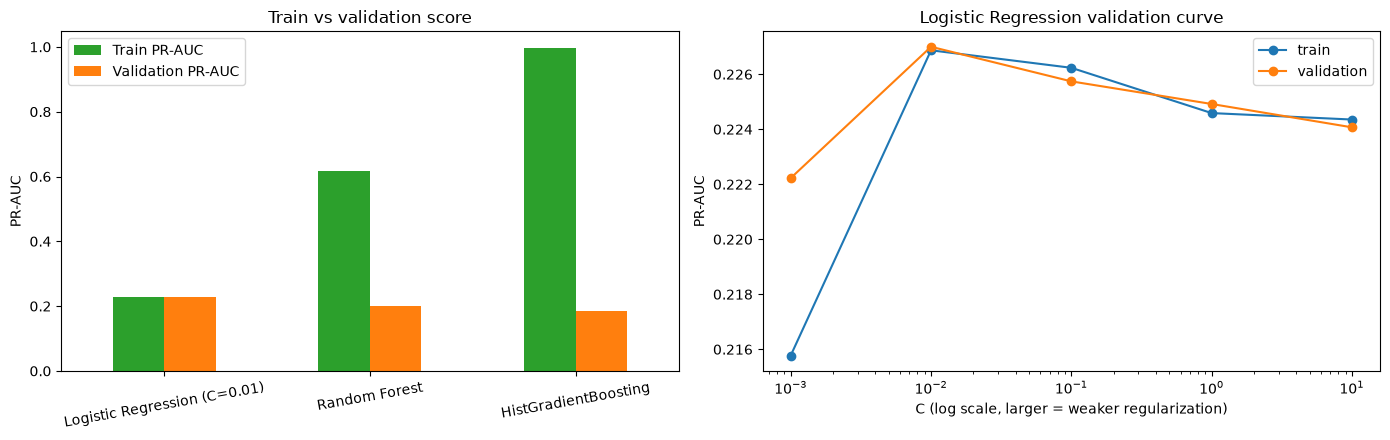

In [13]:
import matplotlib.pyplot as plt

# train vs validation PR-AUC on the same stratified folds
fit_models = {
    "Logistic Regression (C=0.01)": search.best_estimator_,
    "Random Forest": make_pipeline(preprocessor, models["Random Forest"]),
    "HistGradientBoosting": make_pipeline(preprocessor, models["HistGradientBoosting"]),
}
rows = {}
for name, m in fit_models.items():
    res = cross_validate(m, X_train, y_train, cv=cv, scoring="average_precision", return_train_score=True)
    rows[name] = {"Train PR-AUC": res["train_score"].mean(), "Validation PR-AUC": res["test_score"].mean()}
fit_table = pd.DataFrame(rows).T
fit_table["Gap"] = fit_table["Train PR-AUC"] - fit_table["Validation PR-AUC"]
print(fit_table.round(3))

# left: train vs validation per model; right: validation curve over C
cvr = pd.DataFrame(search.cv_results_)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
fit_table[["Train PR-AUC", "Validation PR-AUC"]].plot(kind="bar", ax=axes[0], rot=10, color=["tab:green", "tab:orange"])
axes[0].set_ylabel("PR-AUC")
axes[0].set_title("Train vs validation score")
axes[1].semilogx(cvr["param_logisticregression__C"].astype(float), cvr["mean_train_score"], "o-", label="train")
axes[1].semilogx(cvr["param_logisticregression__C"].astype(float), cvr["mean_test_score"], "o-", label="validation")
axes[1].set_xlabel("C (log scale, larger = weaker regularization)")
axes[1].set_ylabel("PR-AUC")
axes[1].set_title("Logistic Regression validation curve")
axes[1].legend()
plt.tight_layout()
plt.savefig(Path("../reports/figures") / "fit_diagnosis.png", dpi=150, bbox_inches="tight")
plt.show()

**Findings**

| Model | Train PR-AUC | Validation PR-AUC | Gap | Diagnosis |
|---|---|---|---|---|
| **Logistic Regression (C=0.01)** | 0.227 | 0.227 | 0.000 | **Good fit**, no overfitting |
| Random Forest | 0.616 | 0.200 | 0.417 | **Overfitting** |
| HistGradientBoosting | 0.998 | 0.184 | 0.814 | **Strong overfitting** (memorises the 199 training strokes) |

- Logistic Regression scores the same on train and validation, so it generalizes; its modest PR-AUC is a limit of the data (few features, rare class), not of the model.
- The validation curve (note the very small y-range) shows mild **underfitting** at C = 0.001 (too strong regularization) and a flat plateau from C = 0.01 upward.

## 6. Final test (used once)

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import (classification_report, roc_auc_score, average_precision_score,
                             ConfusionMatrixDisplay, PrecisionRecallDisplay)

Fig_Dir = Path("../reports/figures")
Fig_Dir.mkdir(parents=True, exist_ok=True)

# best_estimator_ is already refit on the full training set
best_model = search.best_estimator_
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=["no stroke", "stroke"], digits=3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 3))
print("PR-AUC :", round(average_precision_score(y_test, y_proba), 3), "| baseline PR-AUC = stroke rate =", round(y_test.mean(), 3))

              precision    recall  f1-score   support

   no stroke      0.988     0.748     0.851       972
      stroke      0.143     0.820     0.244        50

    accuracy                          0.751      1022
   macro avg      0.566     0.784     0.548      1022
weighted avg      0.946     0.751     0.822      1022

ROC-AUC: 0.835
PR-AUC : 0.21 | baseline PR-AUC = stroke rate = 0.049


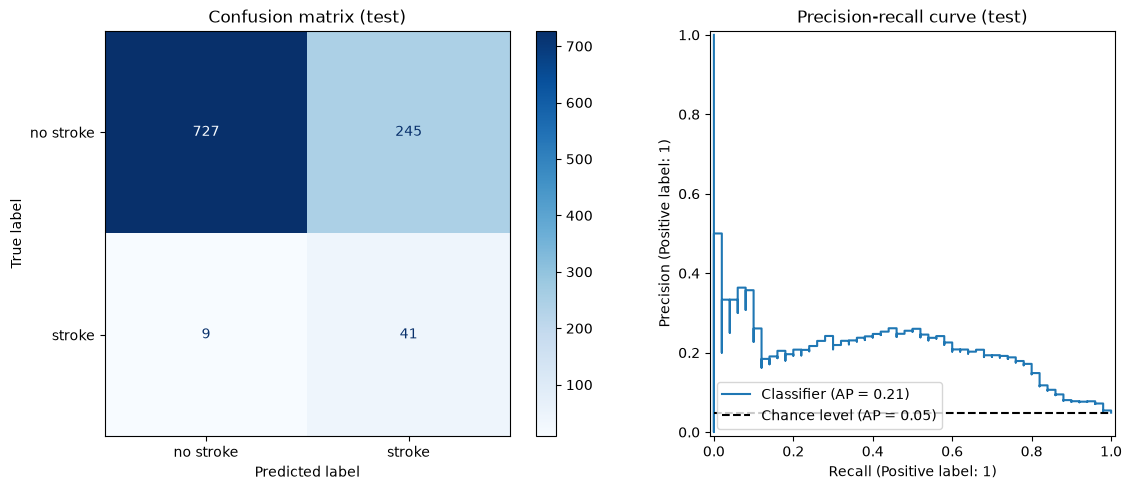

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["no stroke", "stroke"], cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion matrix (test)")
PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=axes[1], plot_chance_level=True)
axes[1].set_title("Precision-recall curve (test)")
plt.tight_layout()
plt.savefig(Fig_Dir / "test_evaluation.png", dpi=150, bbox_inches="tight")
plt.show()

**Test results (1022 patients, 50 strokes)**

| Metric | Value |
|---|---|
| Recall (stroke) | **0.82**: 41 of 50 strokes caught |
| Precision (stroke) | 0.14: about 1 in 7 alarms is a real stroke |
| F1 (stroke) | 0.24 |
| ROC-AUC | 0.835 |
| PR-AUC | 0.21 (4× the 0.049 chance level) |

The model trades precision for recall on purpose: as a **screening tool**, a false alarm costs a follow-up check, while a missed stroke can cost a life. Test results match CV, so the model generalizes.

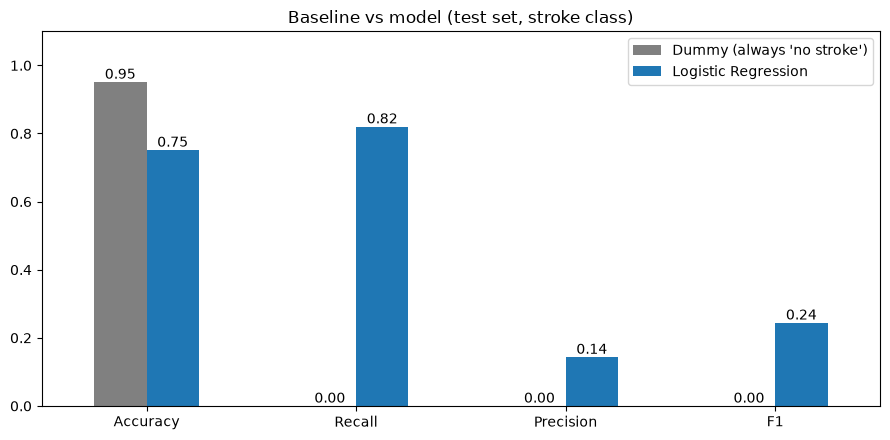

In [16]:
from sklearn.metrics import recall_score, f1_score

# baseline vs model on the test set
dummy = make_pipeline(preprocessor, DummyClassifier(strategy="most_frequent")).fit(X_train, y_train)
preds = {"Dummy (always 'no stroke')": dummy.predict(X_test), "Logistic Regression": y_pred}

compare = pd.DataFrame({
    name: {"Accuracy": (p == y_test).mean(),
           "Recall": recall_score(y_test, p),
           "Precision": precision_score(y_test, p, zero_division=0),
           "F1": f1_score(y_test, p)}
    for name, p in preds.items()
})

ax = compare.plot(kind="bar", figsize=(9, 4.5), rot=0, color=["grey", "tab:blue"])
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f")
ax.set_ylim(0, 1.1)
ax.set_title("Baseline vs model (test set, stroke class)")
plt.tight_layout()
plt.savefig(Fig_Dir / "baseline_vs_model.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** the dummy has the *higher* accuracy (0.95) yet catches no strokes at all, which is why accuracy is the wrong metric here. The model gives up accuracy to catch 82% of strokes.

## 7. What drives the prediction
Logistic Regression coefficients: positive = raises stroke risk, negative = lowers it. Numeric features are scaled; binary/one-hot features are 0/1, so compare sizes only roughly.

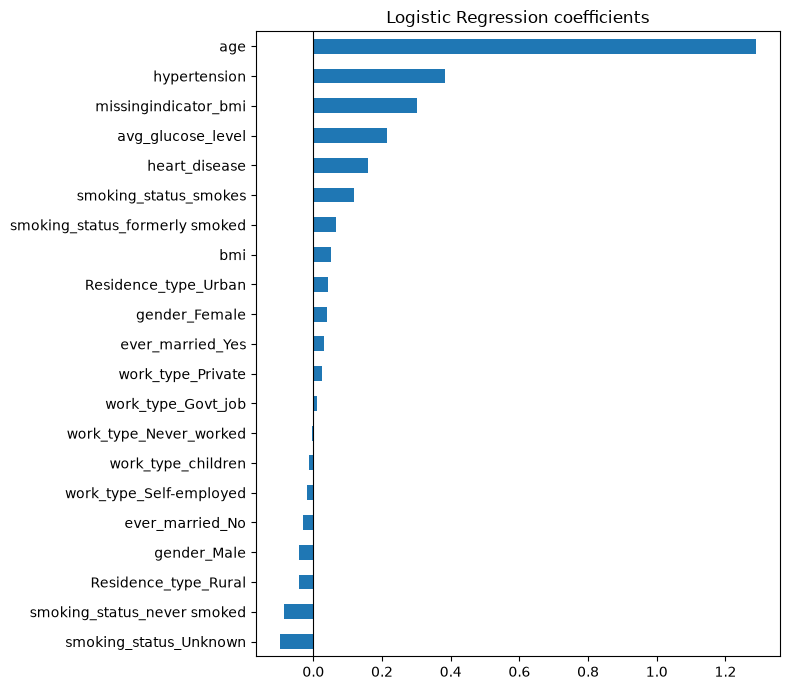

In [17]:
# strip the transformer prefixes (e.g. "pipeline__age" -> "age") for readable labels
names = [n.split("__", 1)[1] for n in best_model[0].get_feature_names_out()]
coefs = pd.Series(best_model[-1].coef_[0], index=names).sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
coefs.plot(kind="barh", ax=ax, title="Logistic Regression coefficients")
ax.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.savefig(Fig_Dir / "coefficients.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** age is by far the strongest risk factor, followed by hypertension, missing BMI, glucose level and heart disease, which matches the EDA and medical knowledge. Gender, residence and work type add almost nothing.

## 8. Save the model
The saved pipeline includes the preprocessing, so the app can pass raw patient values straight in.

In [18]:
import joblib

Model_Dir = Path("../models")
Model_Dir.mkdir(parents=True, exist_ok=True)
joblib.dump(best_model, Model_Dir / "stroke_model.joblib")

# reload to confirm it predicts the same
loaded = joblib.load(Model_Dir / "stroke_model.joblib")
print((loaded.predict(X_test) == y_pred).all())

True


## 9. Monitoring & maintenance plan
The model is deployed as a Streamlit app (one prediction per request, response in well under a second). In production we would:
1. **Monitor performance:** track recall and precision on confirmed outcomes (did flagged / non-flagged patients actually have a stroke?), plus the share of patients flagged.
2. **Watch for data drift:** compare new patients' age, glucose, BMI and category mix with the training data; a different population (e.g. another hospital or country) needs re-validation.
3. **Retrain:** when recall drops or drift is detected, retrain and re-tune with the same stratified CV, and re-check the decision threshold.
4. **Collect feedback:** log inputs and clinician feedback on false alarms and missed cases to improve features and the threshold.